In [18]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import zipfile
from google.colab import files
tf.keras.utils.set_random_seed(42)

In [19]:
ruta = Path("/content/men-women.zip")
if not ruta.exists():
    files.upload()
with zipfile.ZipFile(ruta) as z:
    z.extractall("/content/datos")
base = Path("/content/datos/men-women")
clases = ["man", "woman"]
for parte in ["train", "val", "test"]:
    print(parte, {k: len(list((base/parte/k).glob("*"))) for k in clases})


train {'man': 400, 'woman': 400}
val {'man': 200, 'woman': 200}
test {'man': 200, 'woman': 200}


In [20]:
def cargar(parte):
    return tf.keras.utils.image_dataset_from_directory(base/parte, class_names=clases, image_size=(224,224), batch_size=32, shuffle=(parte=="train"), seed=42)
train, val, test = [cargar(p) for p in ["train", "val", "test"]]
train = train.prefetch(tf.data.AUTOTUNE)
val = val.prefetch(tf.data.AUTOTUNE)
test = test.prefetch(tf.data.AUTOTUNE)


Found 800 files belonging to 2 classes.
Found 400 files belonging to 2 classes.
Found 400 files belonging to 2 classes.


In [21]:
red = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights="imagenet")
red.trainable = False
entrada = tf.keras.Input((224,224,3))
x = tf.keras.layers.Rescaling(1/127.5, offset=-1)(entrada)
x = red(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
salida = tf.keras.layers.Dense(2, activation="softmax")(x)
modelo = tf.keras.Model(entrada, salida)
modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
historia = modelo.fit(train, validation_data=val, epochs=4)

Epoch 1/4
25/25 ━━━━━━━━━━━━━━━━━━━━ 15s 326ms/step - accuracy: 0.6975 - loss: 0.5856 - val_accuracy: 0.8925 - val_loss: 0.2889
Epoch 2/4
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.9125 - loss: 0.2583 - val_accuracy: 0.8925 - val_loss: 0.2371
Epoch 3/4
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9212 - loss: 0.2156 - val_accuracy: 0.8925 - val_loss: 0.2274
Epoch 4/4
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9325 - loss: 0.1886 - val_accuracy: 0.9075 - val_loss: 0.2090


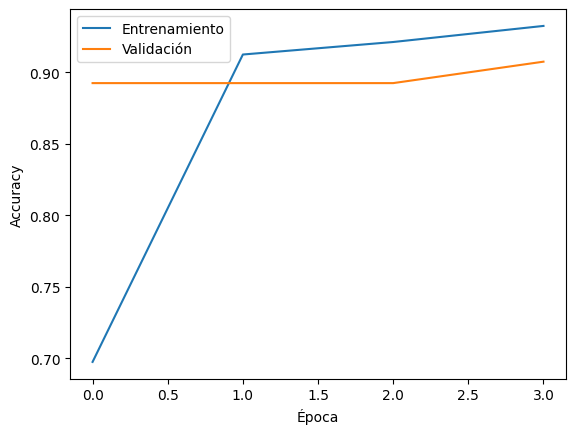

In [22]:
plt.plot(historia.history["accuracy"], label="Entrenamiento")
plt.plot(historia.history["val_accuracy"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 271ms/step - accuracy: 0.8800 - loss: 0.2763
Accuracy de prueba: 88.00%
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 326ms/step
              precision    recall  f1-score   support

         man       0.94      0.81      0.87       200
       woman       0.84      0.94      0.89       200

    accuracy                           0.88       400
   macro avg       0.89      0.88      0.88       400
weighted avg       0.89      0.88      0.88       400



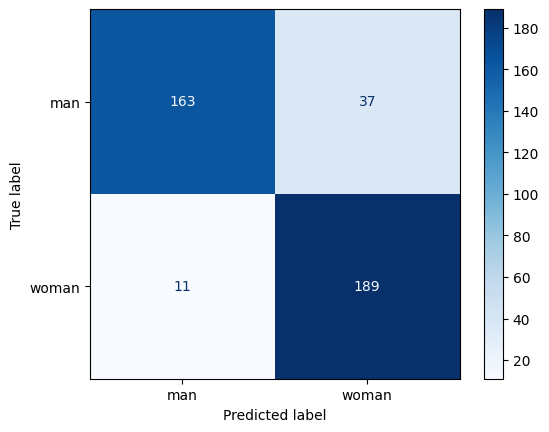

In [23]:
perdida, exactitud = modelo.evaluate(test)
print(f"Accuracy de prueba: {exactitud:.2%}")
y = np.concatenate([etiquetas.numpy() for _, etiquetas in test])
prob = modelo.predict(test)
pred = prob.argmax(axis=1)
print(classification_report(y, pred, labels=[0,1], target_names=clases, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y,pred,display_labels=clases,cmap="Blues")
plt.show()


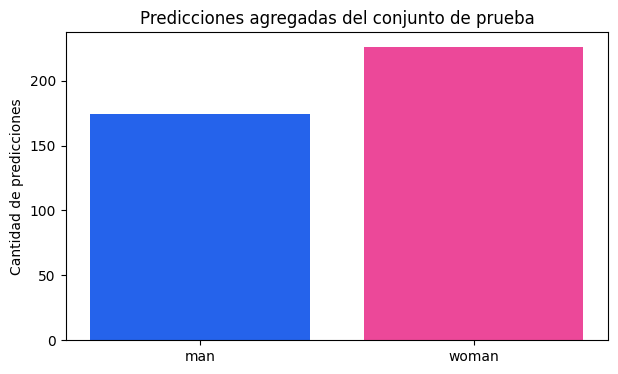

In [24]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(clases, [sum(pred==0),sum(pred==1)], color=["#2563eb","#ec4899"])
ax.set_ylabel("Cantidad de predicciones")
ax.set_title("Predicciones agregadas del conjunto de prueba")
plt.show()


In [25]:
modelo.save("modelo_men_women.keras")
import json
with open("metricas.json","w") as f:
    json.dump({"accuracy":float(exactitud),"clases":clases,"reporte":classification_report(y,pred,labels=[0,1],target_names=clases,output_dict=True,zero_division=0)},f,indent=2)
files.download("modelo_men_women.keras")
files.download("metricas.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

import cv2
import numpy as np
import base64
import json
import time

from google.colab.output import eval_js
from IPython.display import display, Javascript

# Configurar cámara y funciones JavaScript
display(Javascript("""
window.iniciarCamara = async function() {

    const contenedor = document.createElement('div');

    window.video = document.createElement('video');
    window.video.style.display = 'none';

    window.salida = document.createElement('img');
    window.salida.style.width = '640px';

    const boton = document.createElement('button');
    boton.textContent = 'Detener cámara';

    window.activo = true;

    boton.onclick = function() {
        window.detenerCamara();
    };

    contenedor.appendChild(boton);
    contenedor.appendChild(video);
    contenedor.appendChild(salida);

    document.body.appendChild(contenedor);

    window.stream = await navigator.mediaDevices.getUserMedia({
        video: true,
        audio: false
    });

    video.srcObject = stream;
    await video.play();

    return true;
};

window.obtenerFrame = function() {

    if (!window.activo) return null;

    const canvas = document.createElement('canvas');

    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;

    canvas.getContext('2d').drawImage(video, 0, 0);

    return canvas.toDataURL('image/jpeg', 0.8);
};

window.mostrarFrame = function(imagen) {
    window.salida.src = imagen;
};

window.detenerCamara = function() {

    window.activo = false;

    if (window.stream) {
        window.stream.getTracks().forEach(t => t.stop());
    }
};
"""))

# Detector facial OpenCV
detector = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

try:

    eval_js("window.iniciarCamara()")

    while True:

        datos = eval_js("window.obtenerFrame()")

        if datos is None:
            break

        imagen = base64.b64decode(datos.split(",")[1])

        frame = cv2.imdecode(
            np.frombuffer(imagen, dtype=np.uint8),
            cv2.IMREAD_COLOR
        )

        gris = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        rostros = detector.detectMultiScale(
            gris,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(60, 60)
        )

        for x, y, w, h in rostros:

            cv2.rectangle(
                frame,
                (x, y),
                (x+w, y+h),
                (255, 0, 0),
                3
            )

            cv2.putText(
                frame,
                "Rostro detectado",
                (x, max(20, y-10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 0, 0),
                2
            )

        cv2.putText(
            frame,
            f"Rostros: {len(rostros)}",
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        _, buffer = cv2.imencode(".jpg", frame)

        resultado = (
            "data:image/jpeg;base64," +
            base64.b64encode(buffer).decode("utf-8")
        )

        eval_js(
            "window.mostrarFrame(" +
            json.dumps(resultado) + ")"
        )

        time.sleep(0.05)

except KeyboardInterrupt:
    print("Cámara detenida")

finally:
    try:
        eval_js("window.detenerCamara?.()")
    except Exception:
        pass


<IPython.core.display.Javascript object>

In [30]:
import tensorflow as tf

modelo = tf.keras.models.load_model(
    "modelo_men_women.keras",
    compile=False
)

print("Modelo cargado correctamente")
print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

Modelo cargado correctamente
Entrada: (None, 224, 224, 3)
Salida: (None, 2)


In [31]:
clases = ["Man", "Woman"]

colores = {
    "Man": (255, 0, 0),
    "Woman": (180, 105, 255)
}

modelo.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [32]:
from pathlib import Path

for carpeta in Path("/content").rglob("test"):
    if carpeta.is_dir():
        print(carpeta)
        print("Clases:", [
            p.name for p in carpeta.iterdir()
            if p.is_dir()
        ])

/content/datos/men-women/test
Clases: ['man', 'woman']


In [33]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

ruta_test = "/content/datos/men-women/test"

test_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_test,
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

clases = test_ds.class_names

print("Clases:", clases)

Found 400 files belonging to 2 classes.
Clases: ['man', 'woman']


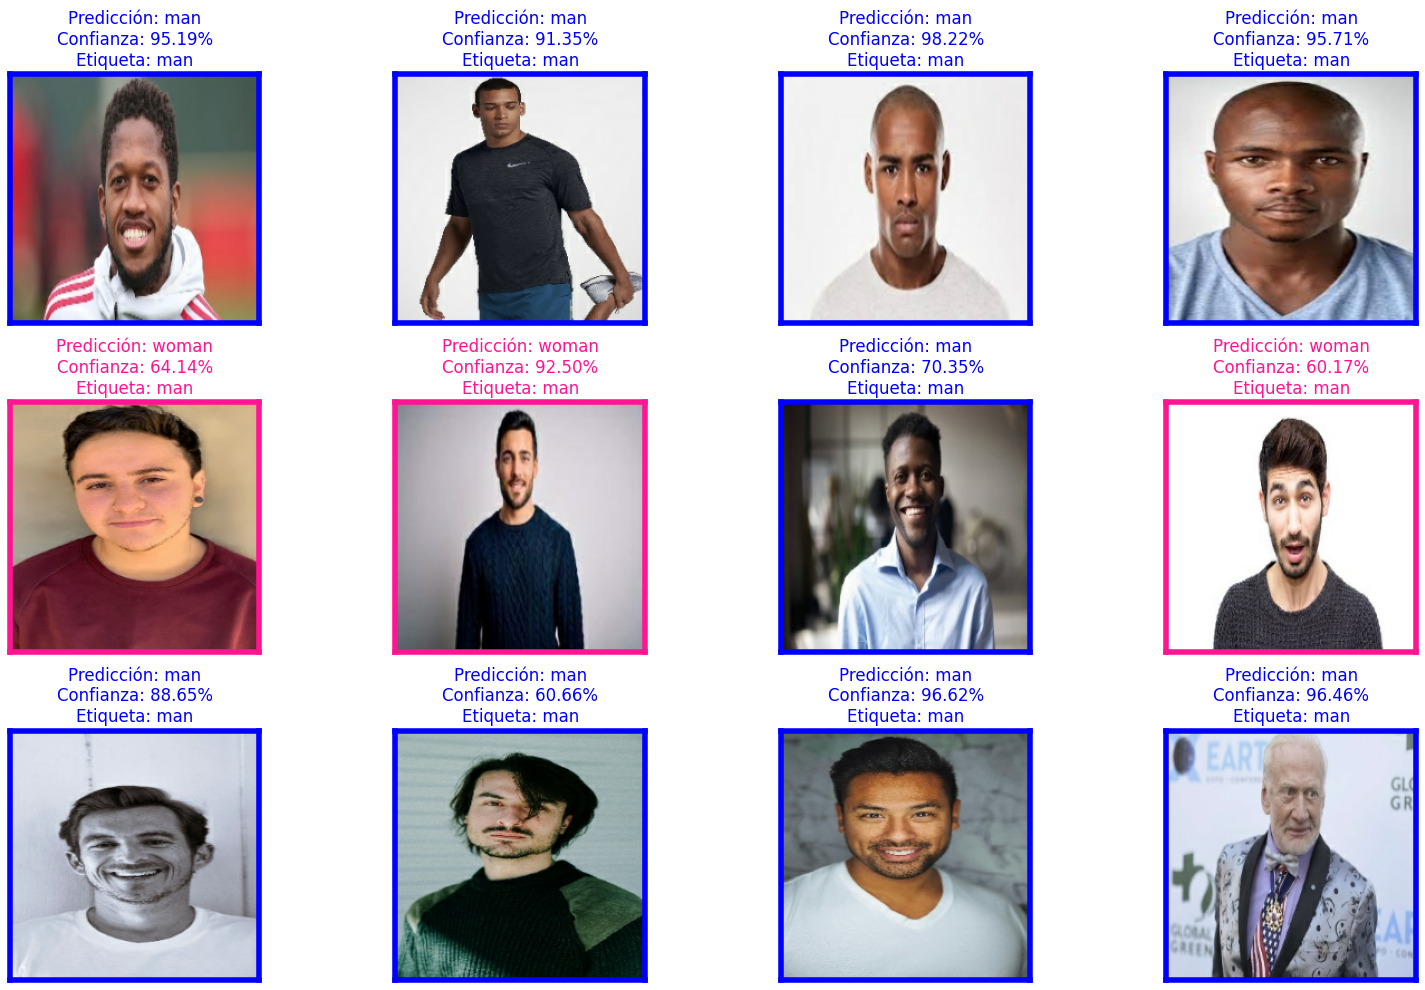

In [34]:
imagenes, etiquetas = next(iter(test_ds))

predicciones = modelo.predict(imagenes, verbose=0)

plt.figure(figsize=(16, 10))

for i in range(12):

    indice = np.argmax(predicciones[i])
    confianza = np.max(predicciones[i]) * 100

    prediccion = clases[indice]
    real = clases[int(etiquetas[i])]

    color = "blue" if prediccion == "man" else "deeppink"

    ax = plt.subplot(3, 4, i + 1)

    plt.imshow(imagenes[i].numpy().astype("uint8"))

    plt.title(
        f"Predicción: {prediccion}\n"
        f"Confianza: {confianza:.2f}%\n"
        f"Etiqueta: {real}",
        color=color
    )

    plt.xticks([])
    plt.yticks([])

    for borde in ax.spines.values():
        borde.set_color(color)
        borde.set_linewidth(4)

plt.tight_layout()
plt.show()

In [35]:
from sklearn.metrics import accuracy_score

y_real = np.concatenate([
    etiquetas.numpy()
    for _, etiquetas in test_ds
])

y_prob = modelo.predict(test_ds, verbose=0)

y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_real, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 88.00%


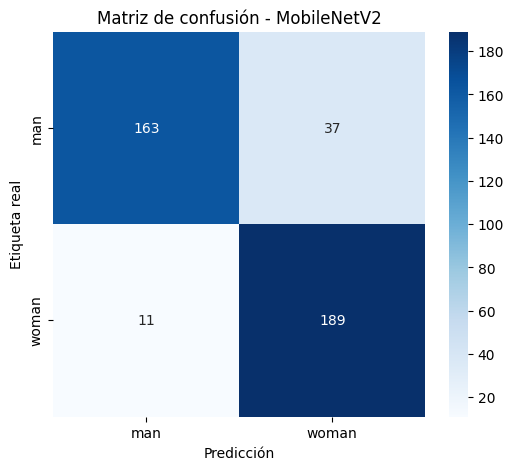

              precision    recall  f1-score   support

         man       0.94      0.81      0.87       200
       woman       0.84      0.94      0.89       200

    accuracy                           0.88       400
   macro avg       0.89      0.88      0.88       400
weighted avg       0.89      0.88      0.88       400



In [36]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns
import matplotlib.pyplot as plt

matriz = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases
)

plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión - MobileNetV2")
plt.show()

print(classification_report(
    y_real,
    y_pred,
    target_names=clases
))

In [37]:
import json
from sklearn.metrics import classification_report

metricas = {
    "accuracy": float(accuracy),
    "total_imagenes": len(y_real),
    "aciertos": int((y_real == y_pred).sum()),
    "errores": int((y_real != y_pred).sum()),
    "matriz_confusion": matriz.tolist(),
    "clases": clases,
    "reporte": classification_report(
        y_real,
        y_pred,
        target_names=clases,
        output_dict=True
    )
}

with open("metricas.json", "w") as archivo:
    json.dump(metricas, archivo, indent=4)

modelo.save("modelo_men_women.keras")

from google.colab import files

files.download("metricas.json")
files.download("modelo_men_women.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>